In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp

In [1]:
data = pd.read_csv('leituras_arduino___.txt',sep = ',')

NameError: name 'pd' is not defined

In [117]:

new_columns = ['x', 'y', 'z','t']
data.columns = new_columns
data.head()

,x,y,z,t
0,0.99,-0.59,-0.0,0.23
1,0.70,-0.74,-0.0,0.33
2,0.95,-0.59,0.0,0.44
3,0.77,-0.64,-0.0,0.49
4,0.90,-0.53,-0.1,0.59


In [118]:
x = np.array(data['x'])
y = np.array(data['y'])
z = np.array(data['y'])
t = np.array(data['t'])

#x = x[61:2508]
#y = y[61:2508]
#z = z[61:2508]
#t = t[61:2508]

mod = np.sqrt(x**2 + y**2 + z**2)

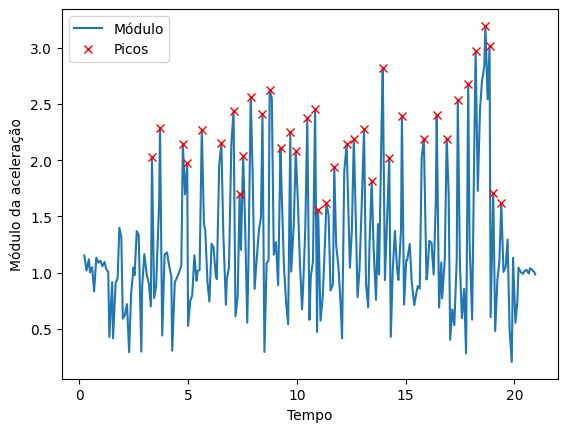

Índices dos picos: [ 35  39  50  52  60  70  76  79  81  85  91  95 100 105 108 114 118 120
 124 128 134 138 143 147 153 156 163 174 181 186 192 197 201 206 208 210
 214]
Valores dos picos: [2.02684484 2.28766256 2.14823183 1.97253644 2.27050655 2.14955809
 2.43511807 1.70387793 2.03816094 2.56119113 2.41132744 2.62213653
 2.11063971 2.25088871 2.07966343 2.37187689 2.45193801 1.56160174
 1.61941347 1.93548444 2.1410745  2.19253278 2.27556586 1.81559907
 2.81923749 2.02338825 2.39645572 2.18908657 2.40141625 2.19317122
 2.53363375 2.68113782 2.97472688 3.19532471 3.01376841 1.70803981
 1.61573513]


In [187]:
import numpy as np
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# Supondo que os dados já estejam carregados
x = np.array(data['x'])
y = np.array(data['y'])
z = np.array(data['z'])
t = np.array(data['t'])

# Calculando o módulo do vetor aceleração
mod = np.sqrt(x**2 + y**2 + z**2)

# Definindo o threshold (limite) para os picos
threshold = 1.5  # Ajuste esse valor conforme necessário

# Encontrando os picos locais no módulo com o threshold
picos, _ = find_peaks(mod, height=threshold)

# Opcional: visualização
plt.plot(t, mod, label='Módulo')
plt.plot(t[picos], mod[picos], 'rx', label='Picos')
plt.xlabel('Tempo')
plt.ylabel('Módulo da aceleração')
plt.legend()
plt.show()

# Picos encontrados
print("Índices dos picos:", picos)
print("Valores dos picos:", mod[picos])


In [188]:
v = sp.integrate.simpson(mod)

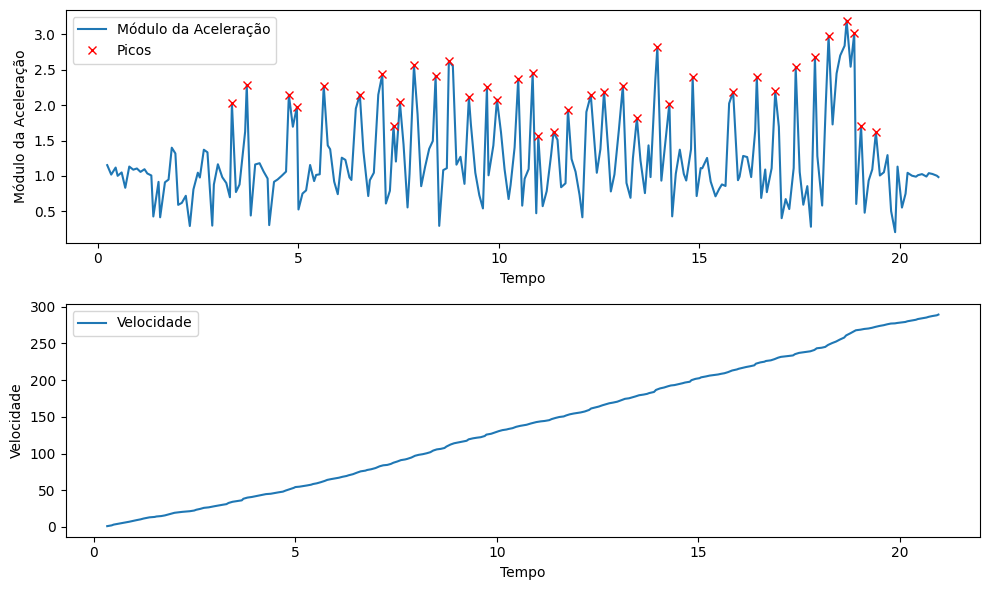

Índices dos picos: [ 35  39  50  52  60  70  76  79  81  85  91  95 100 105 108 114 118 120
 124 128 134 138 143 147 153 156 163 174 181 186 192 197 201 206 208 210
 214]
Valores dos picos: [2.02684484 2.28766256 2.14823183 1.97253644 2.27050655 2.14955809
 2.43511807 1.70387793 2.03816094 2.56119113 2.41132744 2.62213653
 2.11063971 2.25088871 2.07966343 2.37187689 2.45193801 1.56160174
 1.61941347 1.93548444 2.1410745  2.19253278 2.27556586 1.81559907
 2.81923749 2.02338825 2.39645572 2.18908657 2.40141625 2.19317122
 2.53363375 2.68113782 2.97472688 3.19532471 3.01376841 1.70803981
 1.61573513]
Velocidade calculada: [  1.06609066   2.11509466   3.16111694   4.17260699   5.07020843
   6.00934024   7.11444936   8.20597142   9.27978174  10.34831861
  11.41040315  12.42831421  13.05573401  13.63802324  14.22073587
  14.80043632  15.69545828  16.83497179  18.24688833  19.25484884
  19.85375498  20.51673617  20.94379296  21.41577253  22.36853765
  23.40536625  24.61471886  26.00237917  26

In [194]:
import scipy as sp
from scipy.signal import find_peaks
import matplotlib.pyplot as plt


# Supondo que os dados já estejam carregados
x = np.array(data['x'])
y = np.array(data['y'])
z = np.array(data['z'])
t = np.array(data['t'])

# Calculando o módulo do vetor aceleração
mod = np.sqrt(x**2 + y**2 + z**2)

# Definindo o threshold (limite) para os picos
threshold = 1.5  # Ajuste esse valor conforme necessário

# Encontrando os picos locais no módulo com o threshold
picos, _ = find_peaks(mod, height=threshold)

# Cálculo da velocidade (integração numérica do módulo da aceleração)
# Considerando que a aceleração é no módulo, integramos em relação ao tempo
velocidade = sp.integrate.cumulative_simpson(mod)

# Opcional: visualização
plt.figure(figsize=(10, 6))

# Gráfico do módulo da aceleração
plt.subplot(2, 1, 1)
plt.plot(t, mod, label='Módulo da Aceleração')
plt.plot(t[picos], mod[picos], 'rx', label='Picos')
plt.xlabel('Tempo')
plt.ylabel('Módulo da Aceleração')
plt.legend()

# Gráfico da velocidade
plt.subplot(2, 1, 2)
plt.plot(t[1:], velocidade, label='Velocidade')
plt.xlabel('Tempo')
plt.ylabel('Velocidade')
plt.legend()

plt.tight_layout()
plt.show()

# Picos encontrados
print("Índices dos picos:", picos)
print("Valores dos picos:", mod[picos])
print("Velocidade calculada:", velocidade)


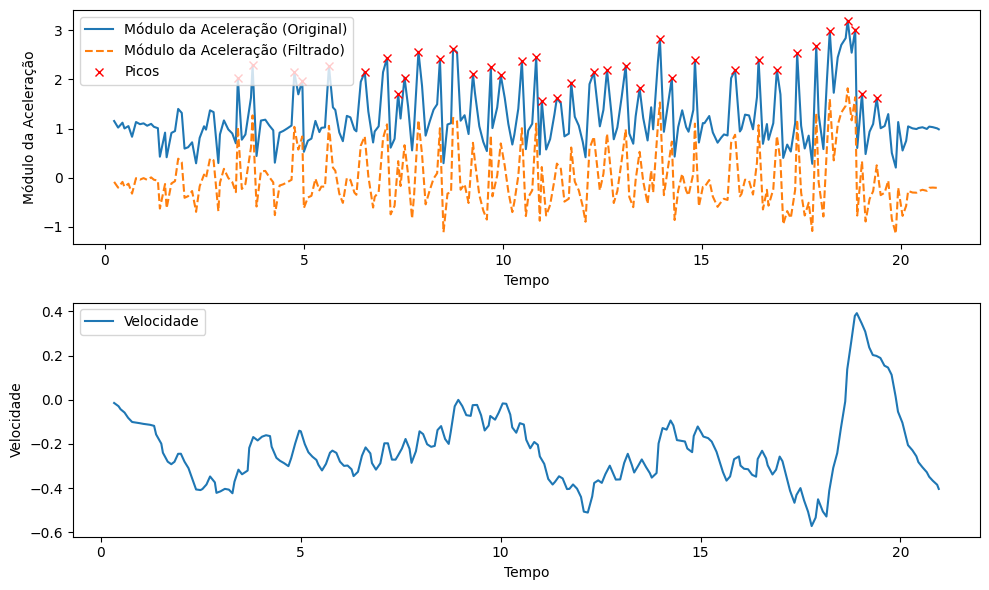

Índices dos picos: [ 35  39  50  52  60  70  76  79  81  85  91  95 100 105 108 114 118 120
 124 128 134 138 143 147 153 156 163 174 181 186 192 197 201 206 208 210
 214]
Valores dos picos: [2.02684484 2.28766256 2.14823183 1.97253644 2.27050655 2.14955809
 2.43511807 1.70387793 2.03816094 2.56119113 2.41132744 2.62213653
 2.11063971 2.25088871 2.07966343 2.37187689 2.45193801 1.56160174
 1.61941347 1.93548444 2.1410745  2.19253278 2.27556586 1.81559907
 2.81923749 2.02338825 2.39645572 2.18908657 2.40141625 2.19317122
 2.53363375 2.68113782 2.97472688 3.19532471 3.01376841 1.70803981
 1.61573513]
Velocidade calculada: [-0.01465089 -0.02932003 -0.04278368 -0.05790109 -0.08180488 -0.10065294
 -0.10337218 -0.1060569  -0.10912666 -0.11152364 -0.11340797 -0.11820712
 -0.15692377 -0.19875848 -0.2397014  -0.28012137 -0.29163663 -0.28063943
 -0.24469948 -0.24431593 -0.28000861 -0.30956607 -0.3598585  -0.40585501
 -0.40867324 -0.40382432 -0.38346615 -0.34714285 -0.37400411 -0.42128473
 -0.4144

In [195]:
import numpy as np
import scipy as sp
from scipy.signal import find_peaks, butter, filtfilt
import matplotlib.pyplot as plt

# Supondo que os dados já estejam carregados
x = np.array(data['x'])
y = np.array(data['y'])
z = np.array(data['z'])
t = np.array(data['t'])

# Calculando o módulo do vetor aceleração
mod = np.sqrt(x**2 + y**2 + z**2)

# Definindo o threshold (limite) para os picos
threshold = 1.5  # Ajuste esse valor conforme necessário

# Encontrando os picos locais no módulo com o threshold
picos, _ = find_peaks(mod, height=threshold)

# Filtro passa-alto Butterworth
# Definindo a frequência de corte (em Hz), e a ordem do filtro
frequencia_corte = 0.1  # Em Hz (ajuste conforme necessário)
ordem_filtro = 4  # Ordem do filtro

# Normalizando a frequência de corte
fs = 1 / (t[1] - t[0])  # Frequência de amostragem (assumindo que t é em segundos)
wn = frequencia_corte / (0.5 * fs)  # Frequência normalizada

# Criando o filtro Butterworth passa-alto
b, a = butter(ordem_filtro, wn, btype='high', analog=False)

# Aplicando o filtro Butterworth no sinal
mod_filtrado = filtfilt(b, a, mod)

# Cálculo da velocidade (integração numérica do módulo da aceleração filtrado)
velocidade = sp.integrate.cumulative_simpson(mod_filtrado, dx=np.mean(np.diff(t)))

# Opcional: visualização
plt.figure(figsize=(10, 6))

# Gráfico do módulo da aceleração original e filtrado
plt.subplot(2, 1, 1)
plt.plot(t, mod, label='Módulo da Aceleração (Original)')
plt.plot(t, mod_filtrado, label='Módulo da Aceleração (Filtrado)', linestyle='--')
plt.plot(t[picos], mod[picos], 'rx', label='Picos')
plt.xlabel('Tempo')
plt.ylabel('Módulo da Aceleração')
plt.legend()

# Gráfico da velocidade
plt.subplot(2, 1, 2)
plt.plot(t[1:], velocidade, label='Velocidade')
plt.xlabel('Tempo')
plt.ylabel('Velocidade')
plt.legend()

plt.tight_layout()
plt.show()

# Picos encontrados
print("Índices dos picos:", picos)
print("Valores dos picos:", mod[picos])
print("Velocidade calculada:", velocidade)
